# Pathways of evolution  

Calculation for the paper *Analyzing $\beta$-Lactamase Evolution from the Principle of Least Action Perspective*

In this notebook we are going to use **FOLDX** trougth **PyFoldX** for the calculation of the protein folding energies ($\Delta \Delta G$). 

In [1]:
import os
# Check FoldX binary location
test = os.getenv('FOLDX_BINARY')
test2 = os.getenv('FOLDX_LOCATION')
print(test, test2)

/home/pablo/Programas/foldx5_Linux/foldx_20270131 /home/pablo/Programas/foldx5_Linux


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from pyfoldx.structure import Structure
from itertools import permutations

## Load structure  

Structure objects created specifying the PDB code.

In [3]:
pdb_code = "1btl"
st=Structure(f"{pdb_code}")
# st=Structure("1BTL.pdb")# XXX At the moment PDB files return errors

### Energy calculations

#### Stability

To compute a whole structure $\Delta G$ we can call the function *getTotalEnergy*, it will return the results of the FoldX Stability command, with the total energy and all the energy terms used to calculate it, in a Pandas DataFrame. 

More information about the FoldX Stability command can be read [here](http://foldxsuite.crg.eu/command/Stability).

In [4]:
st.getTotalEnergy()
# 55.6827

Computing total energy for structure...
Energy computed.


,total,backHbond,sideHbond,energy_VdW,electro,energy_SolvP,energy_SolvH,energy_vdwclash,entrop_sc,entrop_mc,...,cis_bond,energy_torsion,backbone_vdwclash,energy_dipole,water,disulfide,energy_kon,partcov,energyIonisation,entr_complex
1btl,55.6827,-173.469,-66.4273,-282.167,-19.128,406.276,-362.251,14.7529,148.239,389.955,...,1.12406,2.88792,176.546,-0.544024,0,-3.90046,0,0,0.335933,0


#### Repairing a Structure

The FoldX software have a command called [RepairPDB](http://foldxsuite.crg.eu/command/RepairPDB) that minimizes the energy by self mutating\* the sidechain of residues with high energy. This function can be called through the *repair* method of the Structure class.  

We made this first minimization step in order to obtain the same orders of magnitude in the results, beacuse when a aminoacid is mutated with FoldX an structure minization its is carried out, wich modificated the result of the $\Delta \Delta G$.

\* self mutating the sidechain = sidechain rotation.

In [5]:
# We create a new Structure object with the result of the repair() method // 1 minuto 40 seg
# This move the lateral chains and correct the residues based on the residues names in the PDB
stRepaired = st.repair()

Repairing structure...
Structure repaired.


Let's compare the energies of both structures

In [6]:
print("Original Structure energy")
print(st.getTotalEnergy().total)
print()
print("Repaired Structure energy")
print(stRepaired.getTotalEnergy().total)

Original Structure energy
Computing total energy for structure...
Energy computed.
1btl    55.6827
Name: total, dtype: str

Repaired Structure energy
Computing total energy for structure...
Energy computed.
1btl_Repaired    -26.5207
Name: total, dtype: str


As we can see, the energy was minimized and almost 70 Kcal/mol where lost.

In [7]:
# save pdbs
stRepaired.toPdbFile(f"./structures_traj/{pdb_code}_repaired.pdb")
st.toPdbFile(f"./structures_traj/{pdb_code}_original.pdb")

#### Mutating a structure  

To generate mutant models using [FoldX BuildModel](http://foldxsuite.crg.eu/command/BuildModel) command we can call the *mutate* function.  

This function takes as input:  

- The mutations to be performed following the FoldX format: each mutation is separated by comma and is spelled as ORIGINAL_RESIDUE +CHAIN + POSITION + MUTATED_RESIDUE. For example, if we want to mutate the glycine in position 29 of chain I to alanine the mutation code is GI29A.  
- Number of runs, we are going to use `number_of_runs=3` that allow to generate 3 mutants and promediate the $\Delta \Delta G$'s.  

In [8]:
# Trajectories mutations from permutations of all mutations
# Dictionary with pdb code as key and corresponding mutations as values
dict_mut = {"1btl": ["AA42G", "EA104K", "MA182T", "GA238S"],}
# For this calculations we need all the mutation in the permutations
r_p = len(dict_mut[pdb_code])

In [ ]:
# Get the permutations for the corresponding mutations of each pdb 
mut_lst = dict_mut[pdb_code]
mut_traj = list(permutations(mut_lst, r=r_p))

In [10]:
len(mut_traj)

24

In [11]:
# Save the data in pandas dataframe, one column for the mutants, 
# and for columns for each ddg energy (ddG1, ddG2, ddG3, ddG4)
results_df = pd.DataFrame(columns=["Mutants", "ddG1", "ddG2", "ddG3", "ddG4"], 
                          index=range(len(mut_traj)))

In [12]:
# Loop trough the trajectories and save the ddG energies
# Always start with the WT structure (stRepaired object)
for i, traj in enumerate(mut_traj):
    # add mutant traj to dataframe
    results_df.loc[i, "Mutants"] = ",".join(traj)

    for j in range(len(traj)):
        if j == 0:
            muti = traj[j]
        else:
            muti = ",".join([prev,traj[j]])
        # Calculate ddG for the mutation, ignore the rest of results if isn't the last structure in the trajectory
        if j != len(traj)-1:
            energies, _, _ = stRepaired.mutate(f"{muti};", number_of_runs=3, verbose=False)
            # Only save the last mutated struture in the trajectory
        elif j == len(traj)-1:
            energies, mutEnsemble, wtEnsemble = stRepaired.mutate(f"{muti};", number_of_runs=3, verbose=False)
            mutEnsemble.toPdbFile(f"./structures_traj/{pdb_code}_struct_traj_{i}.pdb")
        # Average ddG energy over the number of runs
        # energies["total"] return numbers as strings
        avg_ddg = np.mean([float(val) for val in energies["total"].values])
        # Save the ddG energy in the dataframe
        results_df.loc[i, f"ddG{j+1}"] = float(avg_ddg)
        # update prev mutation
        prev = muti

In [13]:
results_df.head()

,Mutants,ddG1,ddG2,ddG3,ddG4
0,"AA42G,EA104K,MA182T,GA238S",0.728804,0.471949,0.596515,2.734923
1,"AA42G,EA104K,GA238S,MA182T",0.728804,0.471949,2.43987,2.734923
2,"AA42G,MA182T,EA104K,GA238S",0.728804,0.802062,0.596515,2.734923
3,"AA42G,MA182T,GA238S,EA104K",0.728804,0.802062,3.26006,2.725997
4,"AA42G,GA238S,EA104K,MA182T",0.728804,2.664527,2.531193,2.725997


## Ecuation for "functional" energy based in ddG for each mutation  

The ecuation came from the [paper](https://doi.org/10.1007/s00249-025-01809-0) "Vila, J.A. Factors controlling protein evolvability at the molecular scale. Eur Biophys J 55, 101–109 (2026).", and the values of $\Delta \Delta G_{k,U}^{\mu}$ are obtained from FoldX using PyFold. 

$$
P_(path) = \sum_{k=1}^{j} \mathrm{e}^{\beta \Delta \Delta G_{k,U}^{\mu}}
$$

Where $\beta$ is $\beta = \frac{1}{RT} = 1.689$, $R$ stands for the gas constant and $T$ for the absolute temperature in Kelvin degrees, $RT= 0.592$.

In [14]:
def path_ddg(ddG_list, beta=1.689):
    """
    Calculate the probability of each path in the DDG list using the following formula:

    P_(path) = \sum_{k=1}^{j} \mathrm{e}^{\beta \Delta \Delta G_{k,U}^{\mu}}
    \beta = \frac{1}{RT}

    The ddG has the contrary significance to the paper, so we use -ddG in the formula.

    Parameters:
    ddG_list: list, array or pandas series
        List of DDG values for each path.
    beta: float
        The beta parameter (default: 1.689).

    Returns:
    p_path: float  
        The probability of each path based on the DDG values.
    """
    p_path = np.sum([np.exp(beta * (-ddG)) for ddG in ddG_list])
    return p_path

In [15]:
prob_path = results_df[["ddG1", "ddG2", "ddG3", "ddG4"]].apply(path_ddg, axis=1)

In [16]:
results_df["Path_Prob"] = prob_path

In [17]:
results_df.head(5)

,Mutants,ddG1,ddG2,ddG3,ddG4,Path_Prob
0,"AA42G,EA104K,MA182T,GA238S",0.728804,0.471949,0.596515,2.734923,1.117625
1,"AA42G,EA104K,GA238S,MA182T",0.728804,0.471949,2.43987,2.734923,0.768728
2,"AA42G,MA182T,EA104K,GA238S",0.728804,0.802062,0.596515,2.734923,0.925030
3,"AA42G,MA182T,GA238S,EA104K",0.728804,0.802062,3.26006,2.725997,0.564115
4,"AA42G,GA238S,EA104K,MA182T",0.728804,2.664527,2.531193,2.725997,0.327039


In [18]:
# save datframe to csv
results_df.to_csv(f"{pdb_code}_ddg_results.csv", index=False)

In [19]:
# reorder dataframe by Path_Prob
df_reordered = results_df.sort_values(by="Path_Prob")

In [20]:
df_reordered.to_csv(f"{pdb_code}_ddg_reordered.csv", index=False)

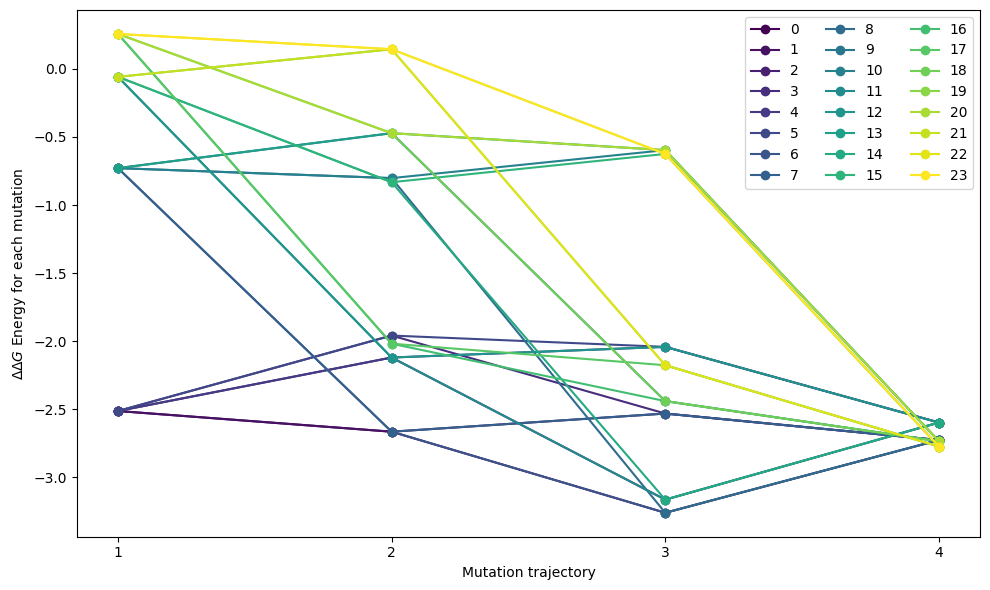

In [21]:
# plot the ddG with a line and dots for each run (each line of ddg in ddg1, ddg2, ddg3, ddg4) 
x_range = range(1, 5)
colors = cm.viridis(np.linspace(0, 1, len(df_reordered)))

plt.figure(figsize=(10, 6))

for i in range(len(df_reordered)): # not .iterrows() for the roeroder index
    plt.plot(x_range, df_reordered[["ddG1", "ddG2", "ddG3", "ddG4"]].iloc[i].values*-1, 
             marker='o', label=f'{i}', color=colors[i])

plt.xlabel("Mutation trajectory")
plt.ylabel(fr"$\Delta \Delta G$ Energy for each mutation")
plt.xticks(x_range)
plt.legend(ncols=3)
# plt.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig("ddg_trajectories.png", dpi=300);